# Merge `Decisao` Classes — 10 → 8

Collapses the 10 fine-grained `Decisao` labels in `preprocessed_grupo3.csv` into 8 by folding two literal near-synonyms of `CONFIRMADA`.

## Section 1 — Setup & Load

Loads the existing 10-class dataset (`preprocessed_grupo3.csv`) and its label map.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

sys.path.insert(0, str(Path('../..').resolve()))
from src.config import DATA_DIR, OUTPUTS_DIR

df = pd.read_csv(DATA_DIR / 'preprocessed_grupo3.csv')
with open(DATA_DIR / 'label2id_grupo3.json', encoding='utf-8') as f:
    label_map_10 = json.load(f)

print(f'Loaded {len(df):,} rows, {df["Decisao"].nunique()} classes')
df['Decisao'].value_counts()

Loaded 10,153 rows, 10 classes


Decisao
CONFIRMADA                        3405
IMPROCEDENTE                      1851
REVOGADA                          1392
PROCEDENTE                         722
NÃO PROVIDO                        579
APELAÇÃO IMPROCEDENTE              540
CONFIRMAÇÃO                        479
REVOGADA EM PARTE                  407
PARCIALMENTE PROCEDENTE            404
CONFIRMADA A DECISÃO RECORRIDA     374
Name: count, dtype: int64

## Section 2 — Define the Merge Mapping

`CLASS_MERGE_MAP` is the single source of truth: every one of the 10 original labels maps to its 8-class group name.

In [2]:
CLASS_MERGE_MAP = {
    'APELAÇÃO IMPROCEDENTE': 'APELAÇÃO IMPROCEDENTE',
    'CONFIRMADA': 'CONFIRMADA',
    'CONFIRMADA A DECISÃO RECORRIDA': 'CONFIRMADA',
    'CONFIRMAÇÃO': 'CONFIRMADA',
    'IMPROCEDENTE': 'IMPROCEDENTE',
    'NÃO PROVIDO': 'NÃO PROVIDO',
    'PARCIALMENTE PROCEDENTE': 'PARCIALMENTE PROCEDENTE',
    'PROCEDENTE': 'PROCEDENTE',
    'REVOGADA': 'REVOGADA',
    'REVOGADA EM PARTE': 'REVOGADA EM PARTE',
}

assert set(CLASS_MERGE_MAP) == set(label_map_10['labels']), (
    'CLASS_MERGE_MAP is missing or has extra original labels vs label2id_grupo3.json'
)

n_target_classes = len(set(CLASS_MERGE_MAP.values()))
print(f'{len(CLASS_MERGE_MAP)} original labels -> {n_target_classes} merged classes')
pd.DataFrame(
    sorted(CLASS_MERGE_MAP.items()), columns=['original_label', 'merged_label'],
)

10 original labels -> 8 merged classes


,original_label,merged_label
0,APELAÇÃO IMPROCEDENTE,APELAÇÃO IMPROCEDENTE
1,CONFIRMADA,CONFIRMADA
2,CONFIRMADA A DECISÃO RECORRIDA,CONFIRMADA
3,CONFIRMAÇÃO,CONFIRMADA
4,IMPROCEDENTE,IMPROCEDENTE
5,NÃO PROVIDO,NÃO PROVIDO
6,PARCIALMENTE PROCEDENTE,PARCIALMENTE PROCEDENTE
7,PROCEDENTE,PROCEDENTE
8,REVOGADA,REVOGADA
9,REVOGADA EM PARTE,REVOGADA EM PARTE


## Section 3 — Apply the Merge

The original label is kept as `Decisao_original` for traceability; `Decisao` is overwritten with the merged label so every downstream.

In [3]:
df['Decisao_original'] = df['Decisao']
df['Decisao'] = df['Decisao_original'].map(CLASS_MERGE_MAP)

assert df['Decisao'].notna().all(), 'Some rows failed to map -- CLASS_MERGE_MAP is incomplete'
assert len(df) == len(df['Decisao_original'].map(CLASS_MERGE_MAP)), 'Row count changed unexpectedly'

before = df['Decisao_original'].value_counts()
after = df['Decisao'].value_counts()

print(f'Before: {len(before)} classes, {before.sum():,} rows')
print(f'After : {len(after)} classes, {after.sum():,} rows')
assert before.sum() == after.sum(), 'Merge changed the total row count'
after

Before: 10 classes, 10,153 rows
After : 8 classes, 10,153 rows


Decisao
CONFIRMADA                 4258
IMPROCEDENTE               1851
REVOGADA                   1392
PROCEDENTE                  722
NÃO PROVIDO                 579
APELAÇÃO IMPROCEDENTE       540
REVOGADA EM PARTE           407
PARCIALMENTE PROCEDENTE     404
Name: count, dtype: int64

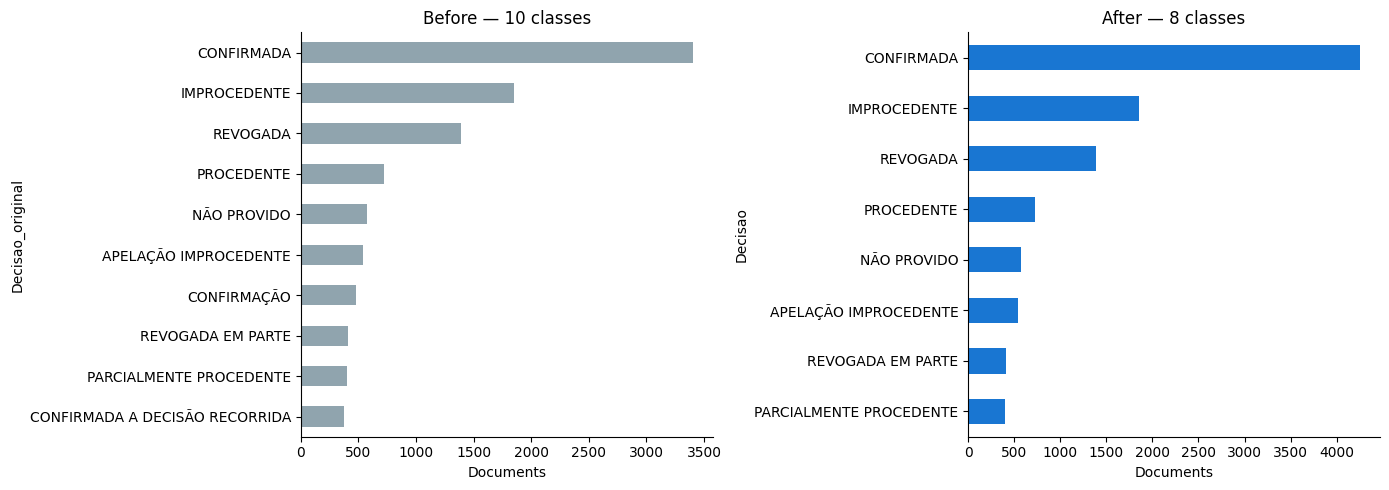

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

before.sort_values().plot.barh(ax=axes[0], color='#90A4AE')
axes[0].set_title(f'Before — {len(before)} classes')
axes[0].set_xlabel('Documents')

after.sort_values().plot.barh(ax=axes[1], color='#1976D2')
axes[1].set_title(f'After — {len(after)} classes')
axes[1].set_xlabel('Documents')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../../reports/figures/class_distribution_8class.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 4 — Sanity Checks

Two things must hold for the merged dataset to stay comparable to every existing 10-class result: the `split` assignment must be completely.

In [5]:
assert set(df['split'].unique()) <= {'train', 'val', 'test'}

split_counts = df.groupby(['split', 'Decisao']).size().unstack('Decisao').fillna(0).astype(int)
split_counts = split_counts.reindex(['train', 'val', 'test'])
print('Rows per class, per split:')
print(split_counts.T.to_string())

train_classes = set(df.loc[df['split'] == 'train', 'Decisao'].unique())
for other_split in ['val', 'test']:
    split_classes = set(df.loc[df['split'] == other_split, 'Decisao'].unique())
    orphans = train_classes - split_classes
    print(f'\nTrain classes absent from {other_split}: {len(orphans)}')
    assert not orphans, f'{orphans} has zero rows in {other_split} -- cannot be evaluated'

Rows per class, per split:
split                    train  val  test
Decisao                                  
APELAÇÃO IMPROCEDENTE      405   54    81
CONFIRMADA                3192  428   638
IMPROCEDENTE              1388  185   278
NÃO PROVIDO                434   58    87
PARCIALMENTE PROCEDENTE    303   40    61
PROCEDENTE                 542   72   108
REVOGADA                  1045  139   208
REVOGADA EM PARTE          305   40    62

Train classes absent from val: 0

Train classes absent from test: 0


## Section 5 — Diagnostic: Collapsing the Existing Confusion Matrix

Retraining every model on the new 8-class labels is the real test.

In [6]:
with open(OUTPUTS_DIR / 'legalbert' / 'finetune' / 'metrics.json', encoding='utf-8') as f:
    legalbert_metrics = json.load(f)

cm_labels_10 = legalbert_metrics['confusion_matrix_labels']
cm_10 = np.array(legalbert_metrics['confusion_matrix'])
assert cm_labels_10 == label_map_10['labels'], 'Confusion matrix label order has drifted from label2id_grupo3.json'

merged_labels = sorted(set(CLASS_MERGE_MAP.values()))
merged_index = {label: i for i, label in enumerate(merged_labels)}

cm_8 = np.zeros((len(merged_labels), len(merged_labels)), dtype=int)
for i, true_label in enumerate(cm_labels_10):
    for j, pred_label in enumerate(cm_labels_10):
        ti = merged_index[CLASS_MERGE_MAP[true_label]]
        pj = merged_index[CLASS_MERGE_MAP[pred_label]]
        cm_8[ti, pj] += cm_10[i, j]

accuracy_10 = np.trace(cm_10) / cm_10.sum()
accuracy_8 = np.trace(cm_8) / cm_8.sum()
print(f'10-class test accuracy (actual)              : {accuracy_10:.4f}')
print(f'8-class test accuracy (collapsed, no retrain) : {accuracy_8:.4f}')
print(f'Delta from collapsing alone                   : {accuracy_8 - accuracy_10:+.4f}')

pd.DataFrame(cm_8, index=merged_labels, columns=merged_labels)

10-class test accuracy (actual)              : 0.4183
8-class test accuracy (collapsed, no retrain) : 0.4747
Delta from collapsing alone                   : +0.0565


,APELAÇÃO IMPROCEDENTE,CONFIRMADA,IMPROCEDENTE,NÃO PROVIDO,PARCIALMENTE PROCEDENTE,PROCEDENTE,REVOGADA,REVOGADA EM PARTE
APELAÇÃO IMPROCEDENTE,25,25,3,2,4,7,11,4
CONFIRMADA,33,375,13,16,8,13,96,84
IMPROCEDENTE,17,24,108,15,41,52,14,7
NÃO PROVIDO,2,4,4,65,4,5,2,1
PARCIALMENTE PROCEDENTE,3,5,8,8,19,12,2,4
PROCEDENTE,9,8,26,3,11,42,6,3
REVOGADA,14,88,3,4,4,6,57,32
REVOGADA EM PARTE,2,20,1,0,3,0,4,32


## Section 6 — Export

Written next to `preprocessed_grupo3.csv` as a distinct file, so nothing about the existing 10-class pipeline is touched.

In [7]:
EXPORT_COLS = [
    'ImportJurisprudenciaId', 'source', 'Sumario_raw', 'Sumario', 'Decisao', 'Decisao_original',
    'TipoDecisao', 'group_id', 'split', 'cv_fold',
]

export_path = DATA_DIR / 'preprocessed_grupo3_8class.csv'
df[EXPORT_COLS].to_csv(export_path, index=False, encoding='utf-8')
print(f'Exported: {export_path}  ({len(df):,} rows)')

le = LabelEncoder().fit(df['Decisao'])
labels_8 = list(le.classes_)
label2id_8 = {cls: int(i) for i, cls in enumerate(le.classes_)}
id2label_8 = {int(i): cls for i, cls in enumerate(le.classes_)}

label_path = DATA_DIR / 'label2id_grupo3_8class.json'
with open(label_path, 'w', encoding='utf-8') as f:
    json.dump(
        {'labels': labels_8, 'label2id': label2id_8, 'id2label': id2label_8},
        f, ensure_ascii=False, indent=2,
    )
print(f'Label mapping saved -> {label_path}  ({len(label2id_8)} classes)')

Exported: <project>/data/2_processed/preprocessed_grupo3_8class.csv  (10,153 rows)
Label mapping saved -> <project>/data/2_processed/label2id_grupo3_8class.json  (8 classes)
